# Residual Convolutional Autoencoder — Trained from Scratch

Train a custom residual CNN to reconstruct normal metal nuts. Anomaly scores come from differences between original and reconstructed images. No pretrained weights or defective training examples are used.

## 1. Setup

Use the same saved normal train/validation split as the baseline and PatchCore. Checkpoints and training history are written locally even if DagsHub is unavailable.

In [1]:
from pathlib import Path
import json
import csv
import random
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import roc_auc_score, average_precision_score

DATA_DIR = Path('../data/raw/metal_nut').resolve()
SPLIT_FILE = Path('../results/normal_split.json').resolve()
MODEL_DIR = Path('../models').resolve()
RESULTS_DIR = Path('../results').resolve()
FIG_DIR = RESULTS_DIR / 'figures'
for directory in (MODEL_DIR, RESULTS_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 8
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
PATIENCE = 8
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
CHECKPOINT = MODEL_DIR / 'residual_autoencoder_best.pt'
HISTORY_PATH = RESULTS_DIR / 'residual_autoencoder_training.csv'
ENABLE_MLFLOW = True  # Set False to run fully offline

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert DATA_DIR.is_dir(), f'Dataset not found: {DATA_DIR}'
assert SPLIT_FILE.is_file(), f'Saved split missing: {SPLIT_FILE}'
print('Device:', DEVICE)
print('Dataset:', DATA_DIR)

Device: mps
Dataset: /Users/chkhai/Documents/projects/inspectAI/data/raw/metal_nut


## 2. Dataset and reproducible split

Only `train/good` images are used for fitting and validation. The official test split stays untouched until the trained model is fixed. No flips are applied because *flip* is itself a defect category.

In [2]:
with open(SPLIT_FILE) as f:
    split = json.load(f)

train_paths = [DATA_DIR / 'train/good' / name for name in split['train']]
val_paths = [DATA_DIR / 'train/good' / name for name in split['validation']]
assert len(train_paths) == 176 and len(val_paths) == 44
assert set(train_paths).isdisjoint(val_paths)
assert all(path.is_file() for path in train_paths + val_paths)

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),  # Pixel range [0, 1], suitable for Sigmoid output
])

class NormalNutDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as im:
            return transform(im.convert('RGB'))

train_loader = DataLoader(NormalNutDataset(train_paths), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0)
val_loader = DataLoader(NormalNutDataset(val_paths), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0)
print(f'Train: {len(train_paths)}, validation: {len(val_paths)}')

Train: 176, validation: 44


## 3. Custom CNN architecture

The encoder uses residual blocks to preserve gradient flow while compressing 256×256 images into 128×16×16 representations. The decoder reconstructs the images using residual blocks and upsampling. All weights start from random initialization, with no pretrained network.

### Residual connections

Each residual block computes `ReLU(F(x) + x)`, giving gradients a shortcut through the block. Unlike U-Net skip connections, these shortcuts stay **within** encoder or decoder stages; they do not pass the original input straight to the output.

In [3]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + residual)


class ResidualAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Four stride-2 reductions: 256 -> 128 -> 64 -> 32 -> 16
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(inplace=True), ResidualBlock(32),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(inplace=True), ResidualBlock(64),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(inplace=True), ResidualBlock(128),
            nn.Conv2d(128, 256, 3, stride=2, padding=1), nn.ReLU(inplace=True), ResidualBlock(256),
            nn.Conv2d(256, 128, 3, stride=2, padding=1), nn.ReLU(inplace=True), ResidualBlock(128),
        )
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(inplace=True), ResidualBlock(128),
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(inplace=True), ResidualBlock(64),
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True), ResidualBlock(32),
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, 3, padding=1), nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

model = ResidualAutoencoder().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

batch = next(iter(train_loader)).to(DEVICE)
with torch.no_grad():
    latent = model.encoder(batch)
    output = model(batch)
assert output.shape == batch.shape
assert latent.shape[1:] == (128, 16, 16)
print('Input/output:', tuple(batch.shape))
print('Latent:', tuple(latent.shape))
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

Input/output: (8, 3, 256, 256)
Latent: (8, 128, 16, 16)
Trainable parameters: 3187107


## 4. Train with early stopping

Optimize MSE reconstruction loss on **normal training images only**. Select the checkpoint with lowest normal validation loss; never use test metrics to choose an epoch. Epoch history is saved locally and optionally logged to MLflow.

In [4]:
# Network logging is best-effort: failure cannot stop local training.
mlflow = None
mlflow_connected = False
if ENABLE_MLFLOW:
    try:
        import dagshub
        import mlflow as _mlflow
        dagshub.init(repo_owner='lchkh23', repo_name='inspectAI', mlflow=True)
        mlflow = _mlflow
        mlflow.set_experiment('metal-nut-anomaly-detection')
        if mlflow.active_run() is not None:
            raise RuntimeError('Another MLflow run is active; close it first.')
        mlflow.start_run(run_name='residual-autoencoder-from-scratch-v1')
        mlflow.log_params({
            'model': 'custom_residual_autoencoder',
            'pretrained': False, 'residual_blocks': True, 'normalization': 'batchnorm', 'input_size': IMAGE_SIZE,
            'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
            'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
            'optimizer': 'adam', 'loss': 'mse', 'seed': SEED,
            'training_samples': len(train_paths), 'validation_samples': len(val_paths),
            'model_selection': 'minimum_normal_validation_mse',
        })
        mlflow_connected = True
        print('MLflow run:', mlflow.active_run().info.run_id)
    except Exception as exc:
        print('MLflow unavailable; local training will continue:', str(exc)[:240])
        mlflow_connected = False

history = []
best_val_loss = float('inf')
best_epoch = 0
bad_epochs = 0
start_time = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_sum, train_count = 0.0, 0
    for images in train_loader:
        images = images.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        reconstructed = model(images)
        loss = criterion(reconstructed, images)
        loss.backward()
        optimizer.step()
        train_sum += loss.item() * len(images)
        train_count += len(images)
    train_loss = train_sum / train_count

    model.eval()
    val_sum, val_count = 0.0, 0
    with torch.inference_mode():
        for images in val_loader:
            images = images.to(DEVICE)
            loss = criterion(model(images), images)
            val_sum += loss.item() * len(images)
            val_count += len(images)
    val_loss = val_sum / val_count

    history.append({'epoch': epoch, 'train_mse': train_loss, 'val_mse': val_loss})
    with open(HISTORY_PATH, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['epoch', 'train_mse', 'val_mse'])
        writer.writeheader()
        writer.writerows(history)

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_epoch = epoch
        bad_epochs = 0
        torch.save({'model_state_dict': model.state_dict(),
                    'epoch': epoch, 'val_mse': val_loss}, CHECKPOINT)
    else:
        bad_epochs += 1

    if mlflow_connected:
        try:
            mlflow.log_metrics({'train_mse': train_loss, 'val_mse': val_loss}, step=epoch)
        except Exception as exc:
            print('MLflow logging failed; continuing locally:', str(exc)[:160])
            mlflow_connected = False

    print(f'Epoch {epoch:02d} | train={train_loss:.5f} | val={val_loss:.5f}')
    if bad_epochs >= PATIENCE:
        print('Early stopping triggered.')
        break

training_seconds = time.perf_counter() - start_time
checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Best epoch: {best_epoch} | best val MSE: {best_val_loss:.6f}')
print(f'Training time: {training_seconds / 60:.1f} minutes')
print('Saved checkpoint:', CHECKPOINT)

Accessing as lchkh23

Initialized MLflow to track repo "lchkh23/inspectAI"

Repository lchkh23/inspectAI initialized!

MLflow run: 225f806cbd224d2fae0158873ce2dace
Epoch 01 | train=0.02117 | val=0.03695
Epoch 02 | train=0.00434 | val=0.01073
Epoch 03 | train=0.00370 | val=0.00327
Epoch 04 | train=0.00297 | val=0.00326
Epoch 05 | train=0.00277 | val=0.00276
Epoch 06 | train=0.00260 | val=0.00277
Epoch 07 | train=0.00272 | val=0.00471
Epoch 08 | train=0.00265 | val=0.00233
Epoch 09 | train=0.00219 | val=0.00209
Epoch 10 | train=0.00205 | val=0.00300
Epoch 11 | train=0.00204 | val=0.00758
Epoch 12 | train=0.00199 | val=0.00212
Epoch 13 | train=0.00227 | val=0.01579
Epoch 14 | train=0.00203 | val=0.00224
Epoch 15 | train=0.00222 | val=0.00198
Epoch 16 | train=0.00176 | val=0.00184
Epoch 17 | train=0.00165 | val=0.00161
Epoch 18 | train=0.00168 | val=0.00158
Epoch 19 | train=0.00161 | val=0.00177
Epoch 20 | train=0.00156 | val=0.00172
Epoch 21 | train=0.00144 | val=0.00143
Epoch 22 | train=0.00146 | val=0.00165
Epoch 23 | train=0.00157 | val=0.00175
Epoch 24 | train=0.00157 | val=0.00164
Epoch 25 | train=0.

## 5. Training curves and reconstructions

Check whether reconstruction improves on held-out normal images. We use these plots for model diagnostics, not to tune against the test set.

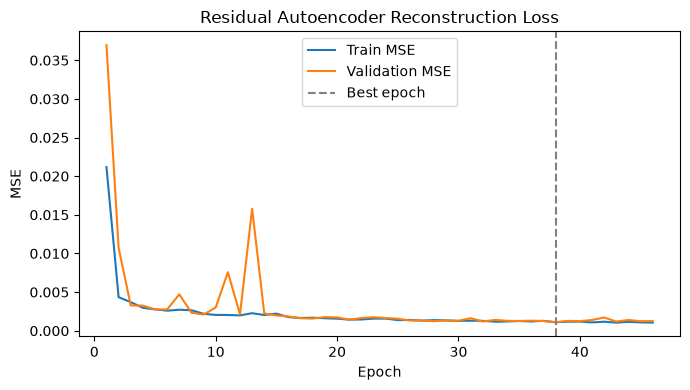

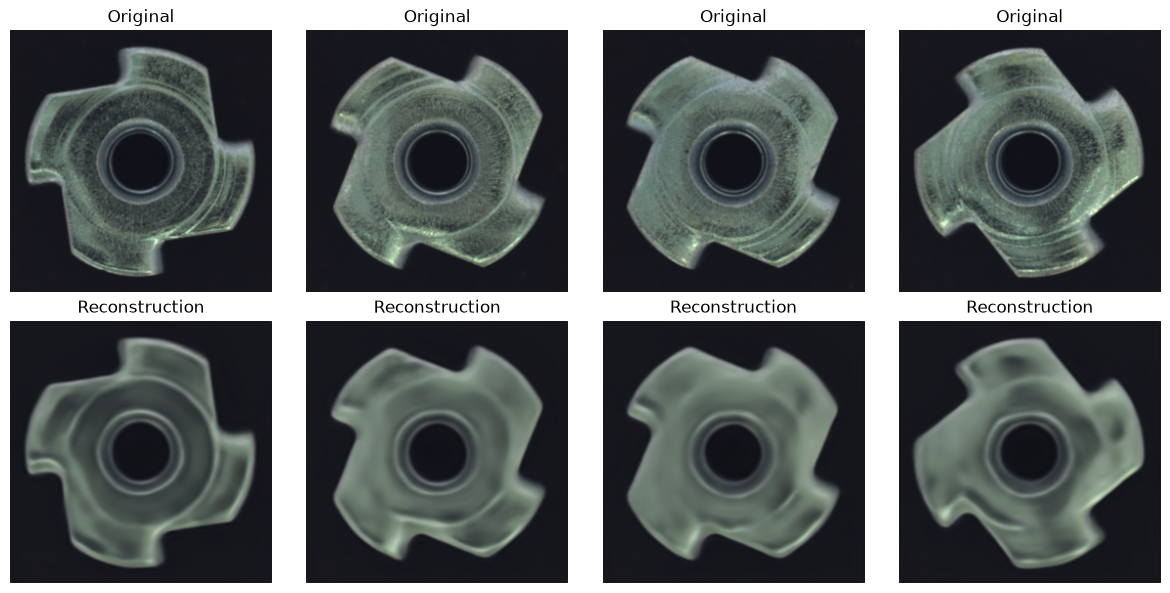

In [5]:
epochs = [row['epoch'] for row in history]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, [row['train_mse'] for row in history], label='Train MSE')
ax.plot(epochs, [row['val_mse'] for row in history], label='Validation MSE')
ax.axvline(best_epoch, linestyle='--', color='gray', label='Best epoch')
ax.set(xlabel='Epoch', ylabel='MSE', title='Residual Autoencoder Reconstruction Loss')
ax.legend()
fig.tight_layout()
curve_path = FIG_DIR / 'residual_autoencoder_loss.png'
fig.savefig(curve_path, dpi=140)
plt.show()

images = next(iter(val_loader))[:4].to(DEVICE)
with torch.inference_mode():
    recon = model(images).cpu().numpy()
orig = images.cpu().numpy()
fig, axes = plt.subplots(2, len(images), figsize=(12, 6))
for j in range(len(images)):
    axes[0, j].imshow(np.transpose(orig[j], (1, 2, 0)))
    axes[1, j].imshow(np.transpose(recon[j], (1, 2, 0)))
    axes[0, j].set_title('Original')
    axes[1, j].set_title('Reconstruction')
    axes[0, j].axis('off')
    axes[1, j].axis('off')
fig.tight_layout()
recon_path = FIG_DIR / 'residual_autoencoder_normal_reconstructions.png'
fig.savefig(recon_path, dpi=140)
plt.show()

## 6. Locked evaluation on the official test set

For each pixel, average the absolute RGB reconstruction error. The image-level anomaly score is the mean of the highest 1% of pixel errors (fixed before test evaluation). Masks are resized with nearest-neighbor interpolation. Report all metrics at 256×256 resolution.

In [6]:
test_samples = []
for category_dir in sorted((DATA_DIR / 'test').iterdir()):
    if not category_dir.is_dir():
        continue
    for path in sorted(category_dir.glob('*.png')):
        test_samples.append((path, int(category_dir.name != 'good'), category_dir.name))

@torch.inference_mode()
def predict_anomaly(image_path):
    with Image.open(image_path) as im:
        x = transform(im.convert('RGB')).unsqueeze(0).to(DEVICE)
    reconstruction = model(x)
    heatmap = (x - reconstruction).abs().mean(dim=1)[0].cpu().numpy()
    flat = heatmap.ravel()
    top_k = max(1, int(np.ceil(flat.size * 0.01)))
    image_score = float(np.partition(flat, -top_k)[-top_k:].mean())
    return image_score, heatmap, reconstruction[0].cpu().numpy()

def load_mask(image_path, category):
    if category == 'good':
        return np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
    mask_path = DATA_DIR / 'ground_truth' / category / f'{image_path.stem}_mask.png'
    assert mask_path.is_file(), f'Missing ground truth: {mask_path}'
    with Image.open(mask_path) as im:
        return (np.array(im.convert('L').resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST)) > 0).astype(np.uint8)

assert len(test_samples) == 115, f'Unexpected test count: {len(test_samples)}'
scores, labels, categories, maps, masks = [], [], [], [], []
for path, label, category in test_samples:
    score, anomaly_map, _ = predict_anomaly(path)
    scores.append(score)
    labels.append(label)
    categories.append(category)
    maps.append(anomaly_map)
    masks.append(load_mask(path, category))

scores = np.asarray(scores)
labels = np.asarray(labels, dtype=np.uint8)
categories = np.asarray(categories)
maps = np.stack(maps).astype(np.float32)
masks = np.stack(masks).astype(np.uint8)

image_auroc = roc_auc_score(labels, scores)
image_ap = average_precision_score(labels, scores)
pixel_auroc = roc_auc_score(masks.ravel(), maps.ravel())
pixel_ap = average_precision_score(masks.ravel(), maps.ravel())
metrics = {'image_auroc': float(image_auroc), 'image_ap': float(image_ap),
           'pixel_auroc': float(pixel_auroc), 'pixel_ap': float(pixel_ap)}

print('=== Residual Autoencoder Results ===')
for name, value in metrics.items():
    print(f'{name}: {value:.4f}')

with open(RESULTS_DIR / 'residual_autoencoder_metrics.json', 'w') as f:
    json.dump({**metrics, 'best_epoch': best_epoch, 'best_val_mse': best_val_loss,
               'train_seconds': training_seconds, 'evaluation_resolution': IMAGE_SIZE}, f, indent=2)
np.savez_compressed(RESULTS_DIR / 'residual_autoencoder_test_predictions.npz',
                    scores=scores, labels=labels, categories=categories,
                    maps=maps, masks=masks)
print('Metrics and predictions saved locally.')

=== Residual Autoencoder Results ===
image_auroc: 0.4027
image_ap: 0.7346
pixel_auroc: 0.7620
pixel_ap: 0.2306
Metrics and predictions saved locally.


## 7. Localization examples

Compare the original image, reconstruction, anomaly map, and ground-truth mask. This is **post-hoc error analysis**, not a reason to retune the model on test images.

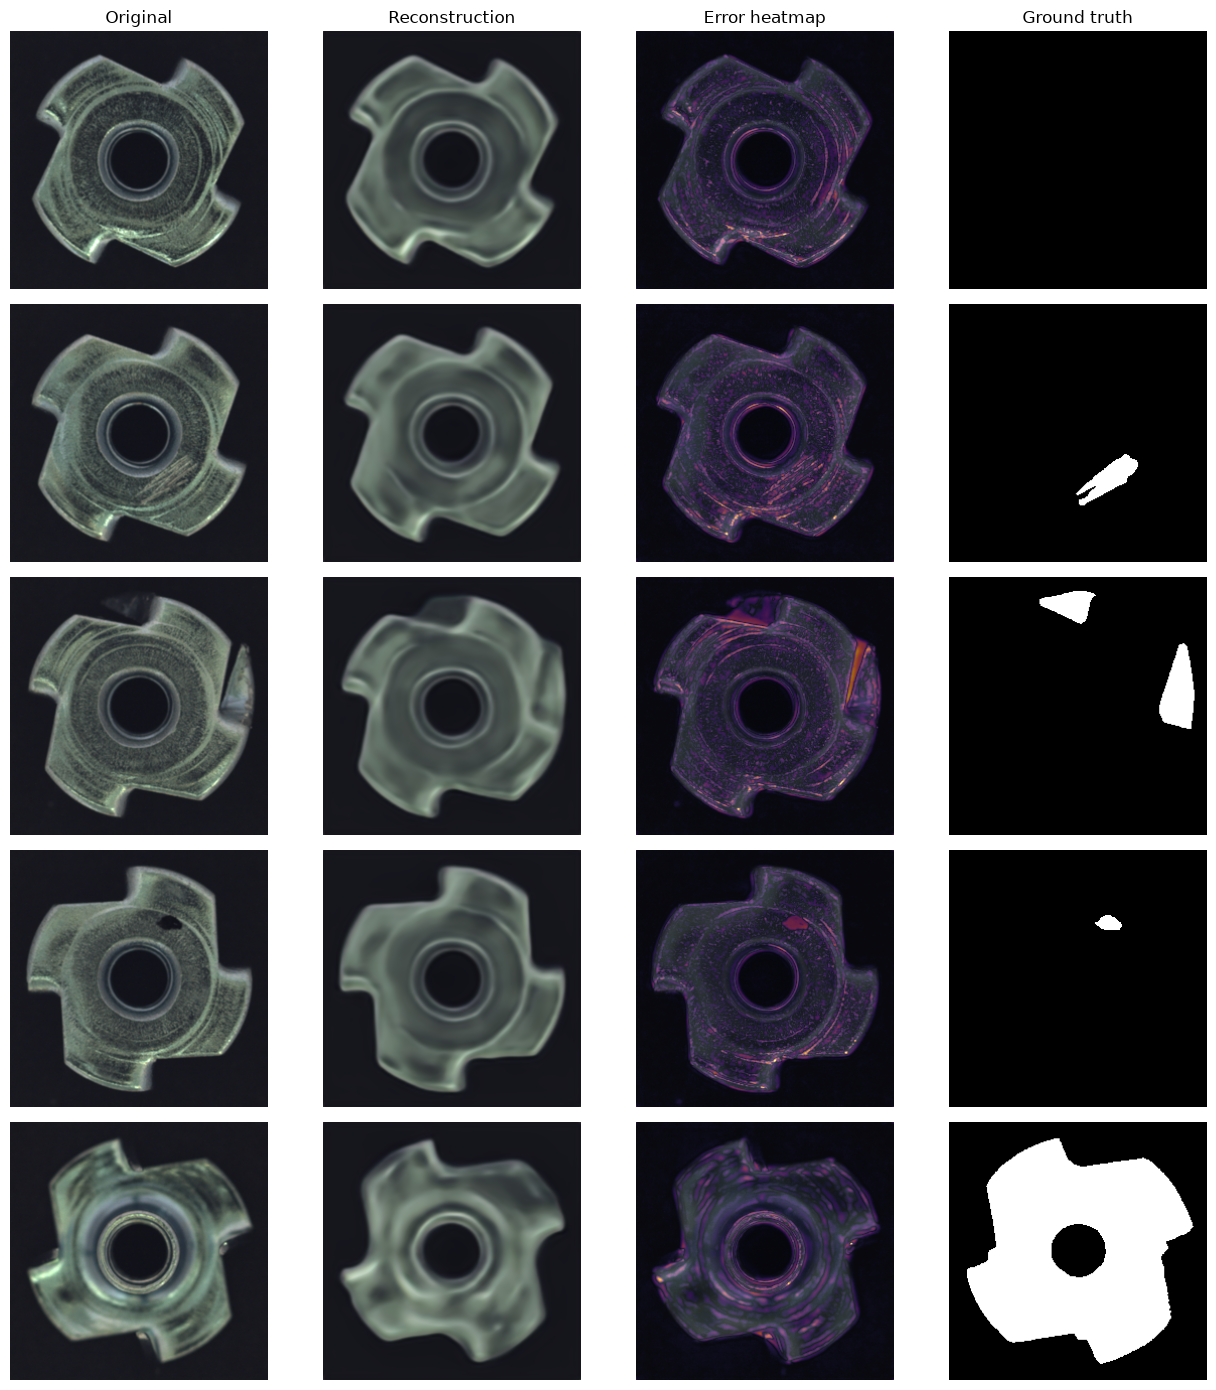

In [7]:
examples = []
for cat in ['good', 'scratch', 'bent', 'color', 'flip']:
    examples.append(next(item for item in test_samples if item[2] == cat))

fig, axes = plt.subplots(len(examples), 4, figsize=(13, 14))
for row, (path, label, category) in enumerate(examples):
    _, heatmap, reconstructed = predict_anomaly(path)
    with Image.open(path) as im:
        original = np.asarray(im.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE)))
    mask = load_mask(path, category)
    axes[row, 0].imshow(original)
    axes[row, 1].imshow(np.transpose(reconstructed, (1, 2, 0)))
    axes[row, 2].imshow(original)
    axes[row, 2].imshow(heatmap, cmap='inferno', alpha=0.6)
    axes[row, 3].imshow(mask, cmap='gray', vmin=0, vmax=1)
    for ax in axes[row]:
        ax.axis('off')
    axes[row, 0].set_ylabel(category, rotation=90, fontsize=11)
for j, title in enumerate(['Original', 'Reconstruction', 'Error heatmap', 'Ground truth']):
    axes[0, j].set_title(title)
fig.tight_layout()
example_path = FIG_DIR / 'residual_autoencoder_localization.png'
fig.savefig(example_path, dpi=140)
plt.show()

## 8. MLflow artifacts and cleanup

Record test metrics and saved outputs. If DagsHub is unreachable, files remain safely stored in `models/` and `results/`. Never rerun training just to retry uploading.

In [8]:
if mlflow is not None and mlflow.active_run() is not None:
    if mlflow_connected:
        try:
            mlflow.log_metrics(metrics)
            mlflow.log_metric('best_epoch', best_epoch)
            mlflow.log_metric('best_val_mse', best_val_loss)
            mlflow.log_metric('train_seconds', training_seconds)
            for artifact in (SPLIT_FILE, CHECKPOINT, HISTORY_PATH, curve_path,
                             recon_path, example_path, RESULTS_DIR / 'residual_autoencoder_metrics.json'):
                mlflow.log_artifact(str(artifact), artifact_path='outputs')
            print('MLflow run artifacts uploaded.')
        except Exception as exc:
            print('Upload failed; local artifacts remain saved:', str(exc)[:240])
    try:
        mlflow.end_run()
    except Exception as exc:
        print('Could not close MLflow run cleanly:', str(exc)[:160])
else:
    print('No active MLflow run; all results are saved locally.')

MLflow run artifacts uploaded.
🏃 View run residual-autoencoder-from-scratch-v1 at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1/runs/225f806cbd224d2fae0158873ce2dace
🧪 View experiment at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1


## 9. Interpretation

Compare this from-scratch residual autoencoder with ResNet18+KNN and PatchCore. Reconstruction error may highlight lighting, background, or texture differences rather than defects. **Do not tune hyperparameters using the official test scores**, which have already been examined in this project. A genuinely independent dataset would be needed to validate generalization.

## Results to share

Print the main metrics and defect-specific image AUROC. These are exploratory test-set results; do not use them to choose a new model configuration.

In [9]:
print('=== Residual Autoencoder Results ===')
print(f'Image AUROC: {image_auroc:.4f}')
print(f'Image AP:    {image_ap:.4f}')
print(f'Pixel AUROC: {pixel_auroc:.4f}')
print(f'Pixel AP:    {pixel_ap:.4f}')
print(f'Best epoch: {best_epoch}')
print(f'Best val MSE: {best_val_loss:.6f}')
print(f'Training time: {training_seconds / 60:.2f} minutes')

print('\nImage AUROC by defect type:')
for category in ['scratch', 'bent', 'color', 'flip']:
    subset = (categories == 'good') | (categories == category)
    print(f'{category.capitalize():8s}: {roc_auc_score(labels[subset], scores[subset]):.4f}')

=== Residual Autoencoder Results ===
Image AUROC: 0.4027
Image AP:    0.7346
Pixel AUROC: 0.7620
Pixel AP:    0.2306
Best epoch: 38
Best val MSE: 0.001098
Training time: 7.21 minutes

Image AUROC by defect type:
Scratch : 0.3340
Bent    : 0.4364
Color   : 0.4607
Flip    : 0.3794
